# Teks — Klasifikasi Teks Multibahasa / Bahasa Daerah
**Kapan dipakai:** teks campuran bahasa Indonesia, Jawa, Sunda, Bali, Minang, dll.
Kata dasar beda-beda tiap bahasa, jadi feature **n-gram huruf** lebih tahan daripada kata.

**Bonus:** identifikasi bahasa (target `bahasa`), pola yang sama, hanya ganti target.

**Awas data paralel:** di NusaX kalimat yang sama diterjemahkan ke 12 bahasa. Split acak
membuat terjemahannya ada di train dan validasi sekaligus (skor validasi palsu tinggi). Jadi
split per kalimat asal (`GroupShuffleSplit`).

**Data demo:** NusaX-senti (12 bahasa, sentimen negative/neutral/positive).

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/text/nusax"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/nusax_train.csv"
TEST_CSV = f"{DATA_FOLDER}/nusax_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/nusax_test_labels.csv"   # hanya ada di data latihan

TEXT_COL = "text"
TARGET = "label"
LANGUAGE_COL = "bahasa"
SENTENCES_PER_LANGUAGE = 600   # baris ke-n tiap bahasa = terjemahan kalimat yang sama
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (7200, 4) | test: (4800, 3)
id        0
text      0
label     0
bahasa    0
dtype: int64


,id,text,label,bahasa
0,0,Nikmati cicilan 0% hingga 12 bulan untuk pemes...,neutral,indonesian
1,1,Kue-kue yang disajikan bikin saya bernostalgia...,positive,indonesian
2,2,Ibu pernah bekerja di grab indonesia,neutral,indonesian
3,3,Paling suka banget makan siang di sini ayam sa...,positive,indonesian
4,4,Pelayanan bus DAMRI sangat baik,positive,indonesian


## EDA: jumlah per bahasa dan label, contoh kalimat

In [4]:
print(pd.crosstab(train[LANGUAGE_COL], train[TARGET]))
for language in ["javanese", "sundanese", "balinese"]:
    first_text = train.loc[train[LANGUAGE_COL] == language, TEXT_COL].iloc[0]
    print(language, "→", first_text[:90])

label        negative  neutral  positive
bahasa                                  
acehnese          230      143       227
balinese          230      143       227
banjarese         230      143       227
buginese          230      143       227
english           230      143       227
indonesian        230      143       227
javanese          230      143       227
madurese          230      143       227
minangkabau       230      143       227
ngaju             230      143       227
sundanese         230      143       227
toba_batak        230      143       227
javanese → Nikmatono cicilan 0% sampek 12 sasi dinggo pesen tiket kapal air asia nganggo kertu kredit
sundanese → Nikmati angsuran 0% dugi ka 12 bulan kanggo mesen tiket pasawat air asia nganggo kartu kir
balinese → Nikmati cicilan 0% kanti 12 bulan antuk pemesanan tiket pesawat air asia nganggen kartu kr


## Bersihkan teks
Huruf beraksen (é, è) dipertahankan karena dipakai di beberapa bahasa daerah.

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|@\w+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s\u00C0-\u024F]", " ", text)
    return text


print(clean_text("Kulo seneng sanget!! @admin http://x.id"))

train[TEXT_COL] = train[TEXT_COL].fillna("").apply(clean_text)
test[TEXT_COL] = test[TEXT_COL].fillna("").apply(clean_text)

kulo seneng sanget      


## Split per kalimat asal
Semua terjemahan satu kalimat masuk ke sisi yang sama (train ATAU validasi).
Data tidak paralel? Ganti dengan `train_test_split` biasa.

In [6]:
source_sentence = train["id"] % SENTENCES_PER_LANGUAGE
splitter = GroupShuffleSplit(test_size=0.2, random_state=SEED)
train_rows, val_rows = next(splitter.split(train, groups=source_sentence))
train_part = train.iloc[train_rows]
val_part = train.iloc[val_rows]
print("train:", train_part.shape, "| validasi:", val_part.shape)

train: (5760, 4) | validasi: (1440, 4)


## Model
Pilih SATU vectorizer dan SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
vectorizer = make_union(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                                        sublinear_tf=True),
                        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True))
# vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
#                              sublinear_tf=True)
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

model = LogisticRegression(C=5, max_iter=3000)
# model = LinearSVC(C=0.3)
# model = SGDClassifier(loss="modified_huber", random_state=SEED)
# model = ComplementNB(alpha=0.3)

pipe = make_pipeline(vectorizer, model)
pipe.fit(train_part[TEXT_COL], train_part[TARGET])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('featureunion', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('tfidfvectorizer-1', ...), ('tfidfvectorizer-2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


## Evaluasi: keseluruhan + per bahasa

In [8]:
val_predictions = pipe.predict(val_part[TEXT_COL])
print("F1 macro:", round(f1_score(val_part[TARGET], val_predictions, average="macro"), 4))
print(classification_report(val_part[TARGET], val_predictions))

per_language = pd.DataFrame()
per_language["asli"] = val_part[TARGET].to_numpy()
per_language["prediksi"] = val_predictions
per_language["bahasa"] = val_part[LANGUAGE_COL].to_numpy()
language_scores = pd.Series(dtype=float)
for language, group in per_language.groupby("bahasa"):
    language_scores[language] = f1_score(group["asli"], group["prediksi"], average="macro")
language_scores.sort_values().round(4)

F1 macro: 0.7324
              precision    recall  f1-score   support

    negative       0.68      0.82      0.74       528
     neutral       0.73      0.53      0.62       300
    positive       0.86      0.82      0.84       612

    accuracy                           0.76      1440
   macro avg       0.76      0.72      0.73      1440
weighted avg       0.77      0.76      0.76      1440



buginese       0.6435
madurese       0.7027
balinese       0.7090
sundanese      0.7225
acehnese       0.7251
ngaju          0.7253
banjarese      0.7377
minangkabau    0.7388
toba_batak     0.7580
english        0.7582
indonesian     0.7599
javanese       0.8000
dtype: float64

## Bonus: identifikasi bahasa (target = kolom `bahasa`)

F1 macro identifikasi bahasa: 0.9862


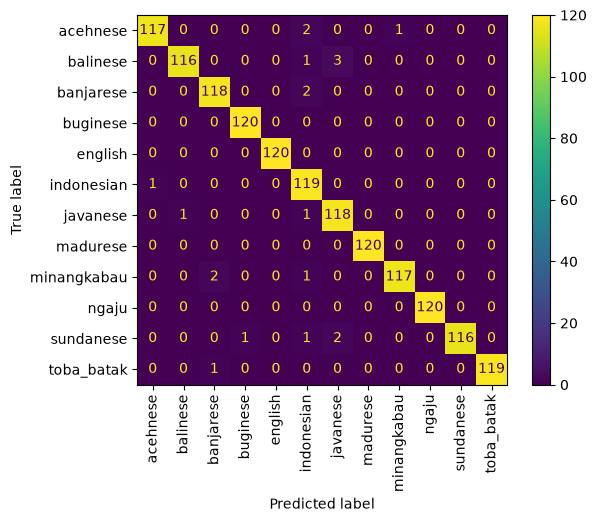

In [9]:
language_pipe = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), min_df=2),
                              LogisticRegression(C=10, max_iter=3000))
language_pipe.fit(train_part[TEXT_COL], train_part[LANGUAGE_COL])
language_predictions = language_pipe.predict(val_part[TEXT_COL])
language_f1 = f1_score(val_part[LANGUAGE_COL], language_predictions, average="macro")
print("F1 macro identifikasi bahasa:", round(language_f1, 4))
ConfusionMatrixDisplay.from_predictions(val_part[LANGUAGE_COL], language_predictions,
                                        xticks_rotation=90)
plt.show()

## Latih ulang di semua data + submission

In [10]:
pipe.fit(train[TEXT_COL], train[TARGET])
predictions = pipe.predict(test[TEXT_COL])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,100000,positive
1,100001,neutral
2,100002,negative
3,100003,positive
4,100004,neutral


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [11]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.748
